# CS781 Phase 6 — Experiment 5: Model 4 + Houlsby Adapters

**Full-data, validation-selected adaptation of the Phase-1 Efficient Decoder (~99.31M).**

- Frozen Phase-1 base; trainable Houlsby adapters after attention and FFN residual sublayers.
- Duplicate-grouped train/validation split; no validation document appears in training.
- Long-document source selection uses head + tail initially; decoding is tuned separately on a disjoint subset.
- Decoding is selected by BERTScore F1 (the official primary metric); ROUGE-1 and ROUGE-L are reported as secondary metrics.
- Integrated improvements: validation/checkpoint every 150 optimizer steps, accurate loss logging, wider decoding grid, resumable test generation, training-curve plot and experiment metadata.
- No external pretrained generator, legal corpus, or LLM API. BERTScore is evaluation-only.

Run top to bottom in a fresh Kaggle session with the Phase-1 Model 4 checkpoint and tokenizer attached as Kaggle input. This notebook deliberately does **not** overwrite your original checkpoint.


In [5]:

!pip -q install tokenizers datasets huggingface_hub bert-score rouge-score nltk scikit-learn tqdm


In [6]:

import os, re, gc, json, math, time, random, hashlib, zipfile, glob, copy
from pathlib import Path
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tokenizers import Tokenizer
from huggingface_hub import hf_hub_download, login
from datasets import load_dataset
from rouge_score import rouge_scorer

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type=="cuda" else "CPU")

ROOT = Path("/kaggle/working/phase6_exp5_model4_houlsby")
ROOT.mkdir(parents=True, exist_ok=True)
OUT_DIR = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)
ADAPTER_DIR = ROOT / "checkpoints"; ADAPTER_DIR.mkdir(exist_ok=True)

# Model 4 Phase-1 architecture: exact values from the uploaded Phase-1 notebook.
VOCAB_SIZE=24576; D_MODEL=640; N_LAYERS=17; N_HEADS=10; N_KV_HEADS=2
FFN_DIM=2048; ROPE_BASE=10000.0; RMS_EPS=1e-5; DROPOUT=0.0
MAX_POSITIONS=2560
ADAPTER_BOTTLENECK=64
ADAPTER_DROPOUT=0.05

# Full-data training. 5% duplicate-grouped holdout; 3 complete epochs.
EPOCHS=3
MICRO_BATCH=1
GRAD_ACCUM=8
LR=2.0e-4
WEIGHT_DECAY=0.01
WARMUP_RATIO=0.05
GRAD_CLIP=1.0
MAX_SOURCE_TOKENS=1500
MAX_TARGET_TOKENS=800
MAX_SEQ_TOKENS=MAX_SOURCE_TOKENS+MAX_TARGET_TOKENS+1
VAL_FRACTION=0.05
SAVE_EVERY=150
VAL_EVERY=150


Device: cuda | Tesla T4


In [7]:

# Locate Phase-1 checkpoint/tokenizer among attached Kaggle datasets.
def find_input_file(patterns):
    hits=[]
    for pat in patterns:
        hits.extend(glob.glob("/kaggle/input/**/"+pat, recursive=True))
    hits=[p for p in hits if os.path.isfile(p)]
    if not hits: return None
    # Prefer the explicit best checkpoint and tokenizer.json.
    hits=sorted(set(hits), key=lambda p: ("best" not in p.lower(), len(p)))
    return hits[0]

BASE_CKPT_PATH = find_input_file(["eff_full_best*.pt", "eff_full_best*.pth"])
TOKENIZER_PATH = find_input_file(["tokenizer.json"])
print("Base checkpoint:", BASE_CKPT_PATH)
print("Tokenizer:", TOKENIZER_PATH)
assert BASE_CKPT_PATH and TOKENIZER_PATH, "Attach Model 4 best checkpoint and tokenizer.json as Kaggle input."

HF_TOKEN=None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN=UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass
if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN)

REPO="Exploration-Lab/CS-781-Capstone"
train_path=hf_hub_download(REPO, "Phase_6_Summ/Train/train.json", repo_type="dataset", token=HF_TOKEN)
test_path=hf_hub_download(REPO, "Phase_6_Summ/Test/test.json", repo_type="dataset", token=HF_TOKEN)
def read_json_records(path):
    obj=json.load(open(path,encoding="utf-8"))
    if isinstance(obj,dict):
        return [dict(id=str(k), **v) for k,v in obj.items()]
    return obj
raw_train=read_json_records(train_path)
test_rows=read_json_records(test_path)
train_rows=[r for r in raw_train if isinstance(r.get("document"),str) and isinstance(r.get("summary"),str) and r["document"].strip() and r["summary"].strip()]
print("Raw train:",len(raw_train),"usable:",len(train_rows),"test:",len(test_rows))


Base checkpoint: /kaggle/input/datasets/aaryant23/phase2-model4/eff_full_best (6).pt
Tokenizer: /kaggle/input/datasets/aaryant23/phase2-model4/tokenizer.json
Raw train: 7030 usable: 7028 test: 100


In [11]:

# Duplicate-safe split: exact normalized-document hashes are grouped before assignment.
def norm_doc(s):
    return re.sub(r"\s+"," ",s).strip().lower()
groups={}
for r in train_rows:
    h=hashlib.sha1(norm_doc(r["document"]).encode("utf-8")).hexdigest()
    groups.setdefault(h,[]).append(r)
group_items=list(groups.items())
random.Random(SEED).shuffle(group_items)
n_val=max(1,round(len(train_rows)*VAL_FRACTION))
val_hashes=set(); val_count=0
for h,rs in group_items:
    if val_count<n_val:
        val_hashes.add(h); val_count+=len(rs)
train_data=[]; val_data=[]
for h,rs in group_items:
    (val_data if h in val_hashes else train_data).extend(rs)
assert not ({hashlib.sha1(norm_doc(x["document"]).encode()).hexdigest() for x in train_data} &
            {hashlib.sha1(norm_doc(x["document"]).encode()).hexdigest() for x in val_data})
print("Train:",len(train_data),"Validation:",len(val_data),"duplicate groups:",len(groups))

# Cell 3 — Custom byte-level BPE (same assignment design, scaled up)
BPE_SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]

class LegalBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = int(vocab_size)
        self.merges = []
        self.itos = list(BPE_SPECIALS)
        self.stoi = {t:i for i,t in enumerate(self.itos)}
        self.symbol_bytes = {}
        for b in range(256):
            s = f"{b:02x}"
            self.symbol_bytes[s] = bytes([b])
            self.stoi[s] = len(self.itos)
            self.itos.append(s)
        self._reset_encode_cache()

    @property
    def pad_token_id(self): return self.stoi["<pad>"]
    @property
    def unk_token_id(self): return self.stoi["<unk>"]
    @property
    def bos_token_id(self): return self.stoi["<s>"]
    @property
    def eos_token_id(self): return self.stoi["</s>"]
    def __len__(self): return len(self.itos)

    @staticmethod
    def word_to_symbols(word):
        return [f"{b:02x}" for b in word.encode("utf-8")]

    def _reset_encode_cache(self):
        self._ranks = {(l,r): i for i,(l,r) in enumerate(self.merges)}
        self._word_cache = {}
        self._cache_nmerges = len(self.merges)

    def fit(self, sentences, min_count=2):
        word_counts = Counter()
        seen_chars = 0
        t0 = time.time()

        for sentence in sentences:
            seen_chars += len(sentence)
            word_counts.update(re.findall(r"\S+|\s+", sentence))
            if seen_chars and seen_chars % 10_000_000 < len(sentence):
                print(f"  BPE corpus read: {seen_chars/1e6:.0f}M chars | unique units={len(word_counts):,}", flush=True)

        if min_count > 1:
            word_counts = Counter({w:c for w,c in word_counts.items() if c >= min_count})

        print(f"BPE training units after min_count={min_count}: {len(word_counts):,}")
        print(f"Counting time: {(time.time()-t0)/60:.1f} min")

        words = list(word_counts)
        freqs = [word_counts[w] for w in words]
        syms = [self.word_to_symbols(w) for w in words]

        target_merges = self.vocab_size - len(self.itos)
        pair_counts = Counter()
        pair_words = {}

        for wi, s in enumerate(syms):
            f = freqs[wi]
            for j in range(len(s)-1):
                p = (s[j], s[j+1])
                pair_counts[p] += f
                pair_words.setdefault(p, set()).add(wi)

        heap = [(-c,p) for p,c in pair_counts.items()]
        heapq.heapify(heap)

        for merge_num in range(target_merges):
            best_pair = None
            best_freq = 0
            while heap:
                negc, p = heap[0]
                if pair_counts.get(p,0) == -negc and -negc > 0:
                    best_pair, best_freq = p, -negc
                    break
                heapq.heappop(heap)

            if best_pair is None or best_freq <= 1:
                print("No useful pairs remain.")
                break

            left, right = best_pair
            new_symbol = left + right
            self.merges.append([left,right])
            self.symbol_bytes[new_symbol] = self.symbol_bytes[left] + self.symbol_bytes[right]
            if new_symbol not in self.stoi:
                self.stoi[new_symbol] = len(self.itos)
                self.itos.append(new_symbol)

            touched = set()
            for wi in list(pair_words.get(best_pair, ())):
                old = syms[wi]
                f = freqs[wi]

                # Remove old local pair contributions.
                for j in range(len(old)-1):
                    p = (old[j], old[j+1])
                    pair_counts[p] -= f
                    touched.add(p)

                merged = []
                j = 0
                while j < len(old):
                    if j+1 < len(old) and old[j] == left and old[j+1] == right:
                        merged.append(new_symbol)
                        j += 2
                    else:
                        merged.append(old[j])
                        j += 1
                syms[wi] = merged

                # Add new local pair contributions.
                for j in range(len(merged)-1):
                    p = (merged[j], merged[j+1])
                    pair_counts[p] += f
                    pair_words.setdefault(p, set()).add(wi)
                    touched.add(p)

            pair_words.pop(best_pair, None)

            for p in touched:
                c = pair_counts.get(p,0)
                if c > 0:
                    heapq.heappush(heap, (-c,p))
                else:
                    pair_counts.pop(p, None)

            if (merge_num+1) % 1000 == 0 or merge_num == 0 or merge_num+1 == target_merges:
                print(
                    f"merge {merge_num+1:,}/{target_merges:,} | "
                    f"freq={best_freq:,} | vocab={len(self.itos):,}",
                    flush=True
                )

        self.vocab_size = len(self.itos)
        self._reset_encode_cache()
        print(f"BPE complete: vocab={len(self):,}")
        return self

    def encode_word(self, word):
        if self._cache_nmerges != len(self.merges):
            self._reset_encode_cache()

        hit = self._word_cache.get(word)
        if hit is not None:
            return list(hit)

        symbols = self.word_to_symbols(word)
        ranks = self._ranks

        while len(symbols) > 1:
            best = None
            best_rank = None
            for j in range(len(symbols)-1):
                r = ranks.get((symbols[j], symbols[j+1]))
                if r is not None and (best_rank is None or r < best_rank):
                    best = (symbols[j], symbols[j+1])
                    best_rank = r
            if best is None:
                break

            left, right = best
            merged = []
            j = 0
            while j < len(symbols):
                if j+1 < len(symbols) and symbols[j] == left and symbols[j+1] == right:
                    merged.append(left+right)
                    j += 2
                else:
                    merged.append(symbols[j])
                    j += 1
            symbols = merged

        # Bound cache memory for 500M-token preprocessing.
        if len(self._word_cache) >= 250_000:
            self._word_cache.clear()
        self._word_cache[word] = tuple(symbols)
        return symbols

    def encode(self, text):
        out = []
        unk = self.unk_token_id
        for unit in re.findall(r"\S+|\s+", text):
            for s in self.encode_word(unit):
                out.append(self.stoi.get(s, unk))
        return out

    def decode(self, ids):
        buf = bytearray()
        for idx in ids:
            idx = int(idx)
            if idx < 0 or idx >= len(self.itos):
                raise ValueError(f"invalid token id {idx}")
            tok = self.itos[idx]
            if tok in BPE_SPECIALS:
                continue
            buf.extend(self.symbol_bytes[tok])
        return bytes(buf).decode("utf-8", errors="replace")

    def save_json(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump(
                {"vocab_size":len(self), "merges":self.merges, "itos":self.itos},
                f, ensure_ascii=False
            )

    @classmethod
    def load_json(cls, path):
        obj = json.load(open(path, encoding="utf-8"))
        tok = cls(obj["vocab_size"])
        tok.merges = [list(x) for x in obj["merges"]]
        tok.itos = list(obj["itos"])
        tok.stoi = {t:i for i,t in enumerate(tok.itos)}
        tok.vocab_size = len(tok.itos)

        tok.symbol_bytes = {}
        for b in range(256):
            s=f"{b:02x}"
            tok.symbol_bytes[s]=bytes([b])
        for l,r in tok.merges:
            tok.symbol_bytes[l+r] = tok.symbol_bytes[l] + tok.symbol_bytes[r]

        tok._reset_encode_cache()
        return tok



tokenizer=LegalBPE.load_json(TOKENIZER_PATH)
def enc(s):
    return tokenizer.encode(s)

def dec(ids):
    return tokenizer.decode([int(x) for x in ids])
# Special IDs follow the Phase-1 tokenizer's declared special tokens.
PAD=tokenizer.pad_token_id
UNK=tokenizer.unk_token_id
BOS=tokenizer.bos_token_id
EOS=tokenizer.eos_token_id
assert None not in (PAD,UNK,BOS,EOS), "Tokenizer is missing expected Phase-1 special tokens."
assert len(tokenizer)==VOCAB_SIZE, (tokenizer.get_vocab_size(),VOCAB_SIZE)
print("Tokenizer size/special ids:", len(tokenizer), PAD, UNK, BOS, EOS)


Train: 6677 Validation: 351 duplicate groups: 7001
Tokenizer size/special ids: 24576 0 1 2 3


In [12]:

# Learned sentence-level source selector (fitted only on official training documents).
# This reuses the selector that materially helped the previous Model-4 LoRA experiment.
from tqdm.auto import tqdm
from sklearn.ensemble import HistGradientBoostingRegressor

SELECTOR_FIT_DOCS=2500
SELECTOR_EVAL_DOCS=150
N_TUNE_DOCS=32
N_FINAL_VAL_DOCS=100
SOURCE_BUDGET=MAX_SOURCE_TOKENS
SPACE_IDS=enc(" ")

STOP=set(("a an the and or of to in on at by for with from as is are was were be been being "
          "this that these those it its he she they them his her their which who whom whose what "
          "when where why how not nor but if then than so such there here also any all each other "
          "into upon under over after before between against during without within through can "
          "could may might must shall should will would do does did has have had we you our us your").split())
WORD_RE=re.compile(r"[a-z]{3,}")
_SPLIT=re.compile(r"(?<=[.?!])\s+(?=[A-Z0-9\"'(\[])")
_ABBR=re.compile(r"(?:\b[A-Z]|\b(?:No|Nos|Sec|Secs|Art|Mr|Mrs|Ms|Dr|St|Rs|Ltd|Co|Cr|Pvt|Smt|Shri|Hon|Prof|vs|etc|viz|Ex|Dy|Addl|Govt|Corpn|Bros|para|paras|cl|ss|Pr))\.$")
CUES=["appellant","respondent","petitioner","held","court","section","act","contended","submitted",
      "argued","dismissed","allowed","appeal","tribunal","order","judgment","therefore","accordingly",
      "question","issue","facts","filed","hence","opinion","decision"]
FEAT_NAMES=["relpos","from_start","from_end","log_nsent","log_nwords","n_content",
            "digit_ratio","cap_ratio","tfidf_mean","tf_mean"]+CUES
TFIDF_COL=FEAT_NAMES.index("tfidf_mean")
IDF=None; IDF_DEFAULT=None; GBM=None

def content_words(text):
    return [w for w in WORD_RE.findall(text.lower()) if w not in STOP]

def build_idf(rows):
    df=Counter()
    for r in tqdm(rows,desc="building selector IDF"):
        df.update(set(content_words(r["document"])))
    N=len(rows)
    return {w:math.log((N+1)/(c+1))+1.0 for w,c in df.items()}, math.log(N+1)+1.0

def split_sentences(doc,max_words=80,chunk_words=50):
    parts=_SPLIT.split(doc)
    merged=[]; buf=""
    for p in parts:
        buf=(buf+" "+p) if buf else p
        if _ABBR.search(buf) and len(buf.split())<60: continue
        merged.append(buf); buf=""
    if buf: merged.append(buf)
    out=[]
    for sent in merged:
        sent=sent.strip()
        if not sent: continue
        words=sent.split()
        if len(words)>max_words:
            out.extend(" ".join(words[j:j+chunk_words]) for j in range(0,len(words),chunk_words))
        else: out.append(sent)
    return out

def sentence_features(doc,idf=None,idf_default=None):
    idf=IDF if idf is None else idf
    idf_default=IDF_DEFAULT if idf_default is None else idf_default
    sents=split_sentences(" ".join(doc.split())); n=len(sents)
    toks=[WORD_RE.findall(s.lower()) for s in sents]
    cws=[[w for w in t if w not in STOP] for t in toks]
    tf=Counter(w for c in cws for w in c)
    X=np.zeros((n,len(FEAT_NAMES)),dtype=np.float32)
    for i,(sent,t,c) in enumerate(zip(sents,toks,cws)):
        words=sent.split(); nw=max(1,len(words)); nc=len(c)
        if nc:
            tfidf=sum(math.log1p(tf[w])*idf.get(w,idf_default) for w in c)/nc
            tfm=sum(tf[w] for w in c)/nc
        else: tfidf=tfm=0.0
        X[i,0]=i/max(1,n-1); X[i,1]=min(i,60)/60.0; X[i,2]=min(n-1-i,60)/60.0
        X[i,3]=math.log1p(n); X[i,4]=math.log1p(nw); X[i,5]=nc
        X[i,6]=sum(1 for w in words if any(ch.isdigit() for ch in w))/nw
        X[i,7]=sum(1 for w in words if w[:1].isupper())/nw
        X[i,8]=tfidf; X[i,9]=tfm
        ts=set(t)
        for j,cue in enumerate(CUES):
            if cue in ts: X[i,10+j]=1.0
    return sents,X,cws

def sentence_labels(cws,summary,idf,idf_default):
    summary_words=set(content_words(summary))
    y=np.zeros(len(cws),dtype=np.float32); weights=np.zeros(len(cws),dtype=np.float32)
    for i,c in enumerate(cws):
        u=set(c)
        if len(u)<3: continue
        den=sum(idf.get(w,idf_default) for w in u)
        num=sum(idf.get(w,idf_default) for w in u if w in summary_words)
        y[i]=num/max(den,1e-8); weights[i]=min(len(u),20)
    return y,weights

def fit_selector(rows):
    idf,default=build_idf(rows)
    Xs=[]; ys=[]; ws=[]
    for r in tqdm(rows,desc="selector training features"):
        _,X,cws=sentence_features(r["document"],idf,default)
        y,w=sentence_labels(cws,r["summary"],idf,default)
        keep=w>0
        if keep.any():
            Xs.append(X[keep]); ys.append(y[keep]); ws.append(w[keep])
    X=np.concatenate(Xs); y=np.concatenate(ys); w=np.concatenate(ws)
    print(f"Fitting sentence scorer on {len(y):,} sentences")
    gbm=HistGradientBoostingRegressor(max_iter=200,learning_rate=0.08,max_leaf_nodes=31,
                                      min_samples_leaf=40,random_state=SEED)
    gbm.fit(X,y,sample_weight=w)
    return gbm,idf,default

def headtail_order(n):
    head=0; tail=n-1; out=[]
    while head<=tail:
        for _ in range(2):
            if head<=tail: out.append(head); head+=1
        if head<=tail: out.append(tail); tail-=1
    return out

def priority_order(mode,X):
    n=len(X)
    if mode=="lead": return list(range(n))
    if mode=="headtail": return headtail_order(n)
    if mode=="tfidf": return [int(i) for i in np.argsort(-X[:,TFIDF_COL],kind="stable")]
    if mode=="learned": return [int(i) for i in np.argsort(-GBM.predict(X),kind="stable")]
    raise ValueError(mode)

def pack_sentences(sents,order,budget):
    chosen={}; used=0; failures=0; sp=len(SPACE_IDS)
    for i in order:
        ids=enc(sents[i]); need=len(ids)+(sp if chosen else 0)
        if need<=budget-used:
            chosen[i]=ids; used+=need; failures=0
        else:
            failures+=1
            if failures>=40: break
        if budget-used<4: break
    out=[]
    for j,i in enumerate(sorted(chosen)):
        if j: out.extend(SPACE_IDS)
        out.extend(chosen[i])
    return out,sorted(chosen)

def select_from_features(sents,X,mode):
    if not sents: return [],[]
    return pack_sentences(sents,priority_order(mode,X),SOURCE_BUDGET)

def selector_coverage(selected,cws,summary):
    words=set(content_words(summary))
    if not words: return None
    got=set()
    for i in selected: got.update(cws[i])
    numerator=sum(IDF.get(w,IDF_DEFAULT) for w in words if w in got)
    denominator=sum(IDF.get(w,IDF_DEFAULT) for w in words)
    return numerator/max(denominator,1e-8)

# Keep selector-fit, selector-evaluation, decoding-tuning and final-validation roles separate.
_rng=np.random.default_rng(SEED)
_val_order=_rng.permutation(len(val_data))
selector_eval_rows=[val_data[i] for i in _val_order[:SELECTOR_EVAL_DOCS]]
tune_rows=[val_data[i] for i in _val_order[SELECTOR_EVAL_DOCS:SELECTOR_EVAL_DOCS+N_TUNE_DOCS]]
final_rows=[val_data[i] for i in _val_order[SELECTOR_EVAL_DOCS+N_TUNE_DOCS:
                                            SELECTOR_EVAL_DOCS+N_TUNE_DOCS+N_FINAL_VAL_DOCS]]
assert len(selector_eval_rows)==SELECTOR_EVAL_DOCS
assert len(tune_rows)==N_TUNE_DOCS and len(final_rows)==N_FINAL_VAL_DOCS

fit_rows=random.Random(SEED).sample(train_data,min(SELECTOR_FIT_DOCS,len(train_data)))
print("Fitting selector on training documents only:",len(fit_rows))
_t0=time.time()
GBM,IDF,IDF_DEFAULT=fit_selector(fit_rows)
print(f"Selector fit time: {(time.time()-_t0)/60:.1f} min")

coverage_scores={m:[] for m in ["lead","headtail","tfidf","learned"]}
for r in tqdm(selector_eval_rows,desc="selector coverage evaluation"):
    sents,X,cws=sentence_features(r["document"])
    if not sents: continue
    for mode in coverage_scores:
        _,chosen=select_from_features(sents,X,mode)
        val=selector_coverage(chosen,cws,r["summary"])
        if val is not None: coverage_scores[mode].append(val)
coverage_means={m:float(np.mean(v)) for m,v in coverage_scores.items() if v}
SELECTOR_MODE=max(coverage_means,key=coverage_means.get)
print("Selector coverage:",coverage_means)
print("Selected source selector:",SELECTOR_MODE)

def select_source(text,max_tokens=MAX_SOURCE_TOKENS):
    sents,X,_=sentence_features(text)
    ids,_=select_from_features(sents,X,SELECTOR_MODE)
    if not ids: ids=enc(" ".join(text.split()))[:max_tokens]
    return ids[:max_tokens]

Fitting selector on training documents only: 2500


building selector IDF:   0%|          | 0/2500 [00:00<?, ?it/s]

selector training features:   0%|          | 0/2500 [00:00<?, ?it/s]

Fitting sentence scorer on 327,921 sentences
Selector fit time: 0.6 min


selector coverage evaluation:   0%|          | 0/150 [00:00<?, ?it/s]

Selector coverage: {'lead': 0.36800831496816755, 'headtail': 0.39817351532606354, 'tfidf': 0.38043109453509333, 'learned': 0.40812780436975155}
Selected source selector: learned


In [13]:

# Use the training-fitted sentence selector chosen on a disjoint validation slice.
class SummDataset(Dataset):
    def __init__(self, rows):
        self.items=[]
        for r in rows:
            s=select_source(r["document"])
            t=enc(r["summary"])[:MAX_TARGET_TOKENS]
            if not s or not t: continue
            # Keep source end token as the final prefix token; target starts after it.
            self.items.append((s,t))
    def __len__(self): return len(self.items)
    def __getitem__(self,i): return self.items[i]

def collate(batch):
    B=len(batch)
    L=max(len(s)+len(t)+1 for s,t in batch)
    ids=torch.full((B,L),PAD,dtype=torch.long)
    labels=torch.full((B,L-1),-100,dtype=torch.long)
    for i,(s,t) in enumerate(batch):
        seq=s+t+[EOS]
        ids[i,:len(seq)]=torch.tensor(seq)
        # Predict target tokens and EOS; mask all source-token targets.
        st=len(s)-1; en=len(s)+len(t)
        labels[i,st:en]=torch.tensor(t+[EOS])
    return ids[:,:-1], ids[:,1:], labels

train_ds=SummDataset(train_data)
val_ds=SummDataset(val_data)
train_loader=DataLoader(train_ds,batch_size=MICRO_BATCH,shuffle=True,collate_fn=collate,num_workers=2,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=1,shuffle=False,collate_fn=collate,num_workers=1)
print("Encoded train/val:",len(train_ds),len(val_ds))


Encoded train/val: 6677 351


In [14]:

class HoulsbyAdapter(nn.Module):
    def __init__(self, dim, bottleneck=64, dropout=0.05):
        super().__init__()
        self.down = nn.Linear(dim, bottleneck)
        self.act = nn.GELU()
        self.dropout = nn.Dropout(dropout)
        self.up = nn.Linear(bottleneck, dim)
        nn.init.normal_(self.down.weight, std=0.02)
        nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)
    def forward(self, x):
        return self.up(self.dropout(self.act(self.down(x))))

# Cell 9 — ~99.31M Efficient Modern Decoder: GQA + RoPE + RMSNorm + SwiGLU   (v2)
# Same parameters / same state_dict keys / same maths as v1 (v1 checkpoints load unchanged). What changed:
#   * RoPE cos/sin are gathered ONCE per forward (v1: once per layer = 34 gathers + 17 GPU->CPU syncs per step)
#   * decode steps use the GQA-native path: the 5 query heads of a KV group become 5 query rows, so the cached
#     K/V are never expanded 5x (v1 copied the whole expanded cache every layer at every generated token)
#   * multi-token chunks that follow a cache are now causal (v1 silently made them bidirectional; unused so far)
#   * build_model() so training always starts from fresh weights; embeddings excluded from weight decay in Cell 11

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        dtype = x.dtype
        x32 = x.float()
        x32 = x32 * torch.rsqrt(x32.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x32.to(dtype) * self.weight)


class RotaryTable(nn.Module):
    """cos/sin table (non-persistent buffers -> nothing is added to the state_dict)."""
    def __init__(self, head_dim, max_positions, base=10000.0):
        super().__init__()
        assert head_dim % 2 == 0
        inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2, dtype=torch.float32) / head_dim))
        freqs = torch.outer(torch.arange(max_positions, dtype=torch.float32), inv_freq)
        self.register_buffer("cos_cached", freqs.cos(), persistent=False)
        self.register_buffer("sin_cached", freqs.sin(), persistent=False)
        self.max_positions = max_positions

    def forward(self, position_ids):
        # (B,T) -> two (B,1,T,D/2) tensors, shared by every layer
        return (self.cos_cached[position_ids].unsqueeze(1),
                self.sin_cached[position_ids].unsqueeze(1))


def apply_rope(x, cos, sin):
    # x: (B,H,T,D) with interleaved (even, odd) rotation pairs -- identical convention to v1
    B, H, T, D = x.shape
    cos = cos.to(x.dtype)
    sin = sin.to(x.dtype)
    xp = x.view(B, H, T, D // 2, 2)
    x0, x1 = xp[..., 0], xp[..., 1]
    return torch.stack((x0 * cos - x1 * sin, x0 * sin + x1 * cos), dim=-1).flatten(-2)


class GQACausalSelfAttention(nn.Module):
    GQA_DECODE_PATH = True     # flip to False to fall back to the (slower) expand-K/V path; used by the self-test

    def __init__(self, d_model, n_heads, n_kv_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        assert n_heads % n_kv_heads == 0
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.head_dim = d_model // n_heads
        self.kv_repeat = n_heads // n_kv_heads
        self.dropout = dropout

        self.q_proj = nn.Linear(d_model, n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.o_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, cos, sin, past_kv=None, use_cache=False, key_valid=None):
        B, T, C = x.shape
        H, KV, D = self.n_heads, self.n_kv_heads, self.head_dim

        q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        k = self.k_proj(x).view(B, T, KV, D).transpose(1, 2)
        v = self.v_proj(x).view(B, T, KV, D).transpose(1, 2)

        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)

        past_len = 0
        if past_kv is not None:
            pk, pv = past_kv
            past_len = pk.size(2)
            k = torch.cat([pk, k], dim=2)
            v = torch.cat([pv, v], dim=2)

        new_kv = (k, v) if use_cache else None          # compact cache: only KV heads are stored
        S = k.size(2)
        drop = self.dropout if self.training else 0.0

        # ---------------- single new token (cached decoding): GQA-native, no K/V expansion
        if T == 1 and past_len > 0 and self.GQA_DECODE_PATH:
            qg = q.reshape(B, KV, self.kv_repeat, D)     # head h = kv*rep + r  ->  row r of group kv
            mask = None if key_valid is None else key_valid[:, None, None, :]
            y = F.scaled_dot_product_attention(qg, k, v, attn_mask=mask, dropout_p=drop, is_causal=False)
            y = y.reshape(B, H, 1, D).transpose(1, 2).contiguous().view(B, 1, C)
            return self.o_proj(y), new_kv

        # ---------------- general path (training / prefill / chunks)
        if self.kv_repeat != 1:
            k_attn = k.repeat_interleave(self.kv_repeat, dim=1)
            v_attn = v.repeat_interleave(self.kv_repeat, dim=1)
        else:
            k_attn, v_attn = k, v

        attn_mask, is_causal = None, False
        if T == 1:
            if key_valid is not None:
                attn_mask = key_valid[:, None, None, :]
        elif key_valid is None and past_len == 0:
            is_causal = True                             # fast path used by training
        else:
            qi = torch.arange(T, device=x.device)[:, None] + past_len
            kj = torch.arange(S, device=x.device)[None, :]
            attn_mask = (kj <= qi)[None, None, :, :]
            if key_valid is not None:
                attn_mask = attn_mask & key_valid[:, None, None, :]
                if past_len == 0:                        # left-padding queries keep one safe key (themselves)
                    attn_mask = attn_mask | (kj == qi)[None, None, :, :]

        y = F.scaled_dot_product_attention(
            q, k_attn, v_attn, attn_mask=attn_mask, dropout_p=drop, is_causal=is_causal
        )
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.o_proj(y), new_kv


class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden_dim, dropout):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, hidden_dim, bias=False)
        self.up_proj = nn.Linear(d_model, hidden_dim, bias=False)
        self.down_proj = nn.Linear(hidden_dim, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = F.silu(self.gate_proj(x)) * self.up_proj(x)
        return self.dropout(self.down_proj(x))


class EfficientDecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, ffn_dim, dropout, rms_eps):
        super().__init__()
        self.norm1 = RMSNorm(d_model, rms_eps)
        self.attn = GQACausalSelfAttention(d_model, n_heads, n_kv_heads, dropout)
        self.norm2 = RMSNorm(d_model, rms_eps)
        self.ff = SwiGLU(d_model, ffn_dim, dropout)
        self.resid_drop = nn.Dropout(dropout)
        self.adapter_attn = HoulsbyAdapter(d_model, ADAPTER_BOTTLENECK, ADAPTER_DROPOUT)
        self.adapter_ff = HoulsbyAdapter(d_model, ADAPTER_BOTTLENECK, ADAPTER_DROPOUT)

    def forward(self, x, cos, sin, past_kv=None, use_cache=False, key_valid=None):
        a, new_kv = self.attn(
            self.norm1(x), cos, sin, past_kv=past_kv, use_cache=use_cache, key_valid=key_valid
        )
        x = x + self.resid_drop(a)
        x = x + self.adapter_attn(x)
        x = x + self.ff(self.norm2(x))
        x = x + self.adapter_ff(x)
        return x, new_kv


class EfficientDecoderLM(nn.Module):
    def __init__(
        self, vocab_size, d_model, n_layers, n_heads, n_kv_heads,
        ffn_dim, dropout, max_positions, rope_base, rms_eps
    ):
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.max_positions = max_positions

        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryTable(d_model // n_heads, max_positions, rope_base)

        self.blocks = nn.ModuleList([
            EfficientDecoderBlock(d_model, n_heads, n_kv_heads, ffn_dim, dropout, rms_eps)
            for _ in range(n_layers)
        ])
        self.final_norm = RMSNorm(d_model, rms_eps)

        self.apply(self._init_weights)
        scaled_std = 0.02 / math.sqrt(2 * n_layers)
        for block in self.blocks:
            nn.init.normal_(block.attn.o_proj.weight, mean=0.0, std=scaled_std)
            nn.init.normal_(block.ff.down_proj.weight, mean=0.0, std=scaled_std)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward_hidden(self, input_ids, past_key_values=None, use_cache=False,
                       position_ids=None, key_valid=None):
        B, T = input_ids.shape
        past_len = 0 if past_key_values is None else past_key_values[0][0].size(2)
        if past_len + T > self.max_positions:
            raise ValueError(f"context {past_len + T} exceeds max_positions={self.max_positions}")

        if position_ids is None:
            position_ids = torch.arange(past_len, past_len + T, device=input_ids.device)[None, :].expand(B, T)
        cos, sin = self.rope(position_ids)               # once for all layers (callers keep ids < max_positions)

        x = self.drop(self.token_emb(input_ids))
        new_cache = [] if use_cache else None
        for i, block in enumerate(self.blocks):
            past = None if past_key_values is None else past_key_values[i]
            x, kv = block(x, cos, sin, past_kv=past, use_cache=use_cache, key_valid=key_valid)
            if use_cache:
                new_cache.append(kv)
        return self.final_norm(x), new_cache

    def project(self, hidden):
        return F.linear(hidden, self.token_emb.weight)   # tied token/output embedding


def build_model():
    return EfficientDecoderLM(
        vocab_size=len(tokenizer), d_model=D_MODEL, n_layers=N_LAYERS,
        n_heads=N_HEADS, n_kv_heads=N_KV_HEADS, ffn_dim=FFN_DIM, dropout=DROPOUT,
        max_positions=MAX_POSITIONS, rope_base=ROPE_BASE, rms_eps=RMS_EPS,
    ).to(DEVICE)




In [15]:

# Load the exact Phase-1 base weights. Handle either a full checkpoint or a raw state_dict.
base_obj=torch.load(BASE_CKPT_PATH,map_location="cpu",weights_only=False)
base_state=base_obj.get("model",base_obj.get("state_dict",base_obj))
model=build_model()
missing,unexpected=model.load_state_dict(base_state,strict=False)
print("Base checkpoint load | missing:",len(missing),"unexpected:",len(unexpected))
# Only the two adapter modules per block may be missing in the Phase-1 checkpoint.
bad_missing=[k for k in missing if ".adapter_" not in k]
assert not bad_missing, f"Unexpected missing base weights: {bad_missing[:20]}"
assert not unexpected, f"Unexpected checkpoint keys: {unexpected[:20]}"
# Re-zero adapter up-projections after the parent model's generic initializer.
# This makes the adapted model start functionally identical to the Phase-1 base.
for block in model.blocks:
    nn.init.zeros_(block.adapter_attn.up.weight)
    nn.init.zeros_(block.adapter_attn.up.bias)
    nn.init.zeros_(block.adapter_ff.up.weight)
    nn.init.zeros_(block.adapter_ff.up.bias)

for name,p in model.named_parameters():
    p.requires_grad=(".adapter_attn." in name or ".adapter_ff." in name)
model.to(DEVICE)

# Base + KV-cache smoke test before full training.
model.eval()
with torch.no_grad():
    _dummy=torch.tensor([[BOS, 10, 11, 12]],device=DEVICE)
    with torch.amp.autocast("cuda",dtype=torch.float16,enabled=(DEVICE.type=="cuda")):
        _h,_cache=model.forward_hidden(_dummy,use_cache=True)
        _logits=model.project(_h)
    assert _logits.shape==(1,4,VOCAB_SIZE) and torch.isfinite(_logits).all()
    _next=torch.tensor([[13]],device=DEVICE)
    with torch.amp.autocast("cuda",dtype=torch.float16,enabled=(DEVICE.type=="cuda")):
        _h2,_cache2=model.forward_hidden(_next,past_key_values=_cache,use_cache=True,
                                         position_ids=torch.tensor([[4]],device=DEVICE))
        _logits2=model.project(_h2)
    assert _logits2.shape==(1,1,VOCAB_SIZE) and torch.isfinite(_logits2).all()
del _dummy,_h,_cache,_next,_h2,_cache2,_logits,_logits2
gc.collect()
if DEVICE.type=="cuda": torch.cuda.empty_cache()
model.train()
print("BASE + KV-CACHE SELF-TEST PASSED")
n_all=sum(p.numel() for p in model.parameters())
n_train=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters: {n_all/1e6:.2f}M | trainable adapters: {n_train/1e6:.2f}M ({100*n_train/n_all:.2f}%)")
assert n_train>0 and n_train<0.05*n_all


Base checkpoint load | missing: 136 unexpected: 0
BASE + KV-CACHE SELF-TEST PASSED
Parameters: 102.12M | trainable adapters: 2.81M (2.75%)


In [16]:

# Training: adapter-only updates, mixed precision, gradient accumulation, cosine decay.
optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=LR,weight_decay=WEIGHT_DECAY,betas=(0.9,0.95))
steps_per_epoch=math.ceil(len(train_loader)/GRAD_ACCUM)
total_steps=steps_per_epoch*EPOCHS
warmup=max(1,int(total_steps*WARMUP_RATIO))
def lr_scale(step):
    if step<warmup: return (step+1)/warmup
    progress=(step-warmup)/max(1,total_steps-warmup)
    return 0.1+0.9*0.5*(1+math.cos(math.pi*min(1.0,progress)))
scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_scale)
scaler=torch.amp.GradScaler("cuda",enabled=(DEVICE.type=="cuda"))
best_val=float("inf"); global_step=0
history=[]
def evaluate_loss():
    model.eval(); losses=[]
    with torch.no_grad():
        for x,y,lab in val_loader:
            x=x.to(DEVICE); y=y.to(DEVICE); lab=lab.to(DEVICE)
            with torch.amp.autocast("cuda",dtype=torch.float16,enabled=(DEVICE.type=="cuda")):
                h,_=model.forward_hidden(x)
                logits=model.project(h)
                loss=F.cross_entropy(logits.reshape(-1,VOCAB_SIZE),lab.reshape(-1),ignore_index=-100)
            if torch.isfinite(loss): losses.append(float(loss))
    model.train()
    return float(np.mean(losses)) if losses else float("inf")

for epoch in range(EPOCHS):
    model.train(); optimizer.zero_grad(set_to_none=True)
    running=0.0; t0=time.time()
    for bi,(x,y,lab) in enumerate(train_loader):
        x=x.to(DEVICE,non_blocking=True); lab=lab.to(DEVICE,non_blocking=True)
        with torch.amp.autocast("cuda",dtype=torch.float16,enabled=(DEVICE.type=="cuda")):
            h,_=model.forward_hidden(x)
            logits=model.project(h)
            loss=F.cross_entropy(logits.reshape(-1,VOCAB_SIZE),lab.reshape(-1),ignore_index=-100)
            loss=loss/GRAD_ACCUM
        if not torch.isfinite(loss): raise RuntimeError(f"Non-finite loss at epoch {epoch+1}, batch {bi}")
        scaler.scale(loss).backward(); running+=float(loss.detach())*GRAD_ACCUM
        if (bi+1)%GRAD_ACCUM==0 or (bi+1)==len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],GRAD_CLIP)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
            scheduler.step(); global_step+=1
            if global_step%50==0:
                print(f"epoch {epoch+1}/{EPOCHS} step {global_step}/{total_steps} loss {running/50:.4f} lr {scheduler.get_last_lr()[0]:.2e}",flush=True)
                running=0.0
            if global_step%VAL_EVERY==0 or global_step==total_steps:
                v=evaluate_loss()
                print(f"validation loss @ step {global_step}: {v:.5f}",flush=True)
                history.append({"epoch":epoch+1,"step":global_step,"val_loss":v})
                if v<best_val:
                    best_val=v
                    torch.save({"adapter":{k:v.cpu() for k,v in model.state_dict().items() if ".adapter_" in k},
                                "global_step":global_step,"epoch":epoch+1,"val_loss":v,
                                "config":{"bottleneck":ADAPTER_BOTTLENECK,"source":MAX_SOURCE_TOKENS,"target":MAX_TARGET_TOKENS}},
                               ADAPTER_DIR/"model4_houlsby_best.pt")
                model.train()
            if global_step%SAVE_EVERY==0:
                torch.save({"adapter":{k:v.cpu() for k,v in model.state_dict().items() if ".adapter_" in k},
                            "global_step":global_step,"epoch":epoch+1},
                           ADAPTER_DIR/"model4_houlsby_latest.pt")
    print(f"Epoch {epoch+1} finished in {(time.time()-t0)/60:.1f} min")
json.dump(history,open(ROOT/"training_history.json","w"),indent=2)
print("Best validation loss:",best_val)


epoch 1/3 step 50/2505 loss 12.2761 lr 8.16e-05
epoch 1/3 step 100/2505 loss 11.3533 lr 1.62e-04
epoch 1/3 step 150/2505 loss 11.2474 lr 2.00e-04
validation loss @ step 150: 1.38968
epoch 1/3 step 200/2505 loss 11.3015 lr 2.00e-04
epoch 1/3 step 250/2505 loss 10.8667 lr 1.99e-04
epoch 1/3 step 300/2505 loss 10.6802 lr 1.98e-04
validation loss @ step 300: 1.35069
epoch 1/3 step 350/2505 loss 10.7459 lr 1.96e-04
epoch 1/3 step 400/2505 loss 10.6889 lr 1.94e-04
epoch 1/3 step 450/2505 loss 10.6180 lr 1.92e-04
validation loss @ step 450: 1.33233
epoch 1/3 step 500/2505 loss 10.4329 lr 1.89e-04
epoch 1/3 step 550/2505 loss 10.6592 lr 1.86e-04
epoch 1/3 step 600/2505 loss 10.5104 lr 1.83e-04
validation loss @ step 600: 1.31918
epoch 1/3 step 650/2505 loss 10.4587 lr 1.79e-04
epoch 1/3 step 700/2505 loss 10.5077 lr 1.75e-04
epoch 1/3 step 750/2505 loss 10.4356 lr 1.71e-04
validation loss @ step 750: 1.31074
epoch 1/3 step 800/2505 loss 10.3014 lr 1.67e-04
Epoch 1 finished in 22.3 min
epoch 2/

In [17]:

# Restore validation-best adapters before any generation.
best=torch.load(ADAPTER_DIR/"model4_houlsby_best.pt",map_location="cpu",weights_only=False)
model.load_state_dict(best["adapter"],strict=False)
model.eval()
print("Loaded best adapter:",best["global_step"],best["val_loss"])


Loaded best adapter: 2505 1.2778613113100372


In [18]:

# KV-cached batched generation with left padding, no-repeat n-gram, repetition penalty and min length.
def no_repeat_ban(seq,n):
    if n<2 or len(seq)<n-1: return []
    prefix=tuple(seq[-(n-1):]); banned=[]
    for i in range(len(seq)-n+1):
        if tuple(seq[i:i+n-1])==prefix: banned.append(seq[i+n-1])
    return banned

@torch.no_grad()
def generate_one(source_ids, max_new=800, min_new=120, no_repeat=8, rep=1.05):
    source_ids=source_ids[-MAX_SOURCE_TOKENS:]
    x=torch.tensor(source_ids,device=DEVICE,dtype=torch.long)[None,:]
    with torch.amp.autocast("cuda",dtype=torch.float16,enabled=(DEVICE.type=="cuda")):
        h,cache=model.forward_hidden(x,use_cache=True)
    logits=model.project(h[:,-1:])[:,-1,:].float()
    generated=[]
    for step in range(max_new):
        z=logits.clone()
        z[:,[PAD,UNK,BOS]]=-float("inf")
        if step<min_new: z[:,EOS]=-float("inf")
        if rep!=1.0 and generated:
            unique=torch.tensor(list(set(generated)),device=DEVICE)
            vals=z[:,unique]
            z[:,unique]=torch.where(vals<0,vals*rep,vals/rep)
        banned=no_repeat_ban(generated,no_repeat)
        if banned: z[:,torch.tensor(list(set(banned)),device=DEVICE)]=-float("inf")
        nxt=int(torch.argmax(z,dim=-1).item())
        if nxt==EOS: break
        generated.append(nxt)
        pos=torch.tensor([[x.size(1)+step]],device=DEVICE)
        with torch.amp.autocast("cuda",dtype=torch.float16,enabled=(DEVICE.type=="cuda")):
            h,cache=model.forward_hidden(torch.tensor([[nxt]],device=DEVICE),past_key_values=cache,use_cache=True,position_ids=pos)
            logits=model.project(h[:,-1:])[:,-1,:].float()
    return dec(generated).strip()

gc.collect()
if DEVICE.type=='cuda': torch.cuda.empty_cache()

# tune_rows and final_rows were fixed in the selector cell; all validation roles are disjoint.
print("Selector-eval / decode-tune / final-validation docs:",
      len(selector_eval_rows),len(tune_rows),len(final_rows))


Selector-eval / decode-tune / final-validation docs: 150 32 100


In [19]:

# Decode tuning: compare n-gram blocking and repetition control; select by official primary metric BERTScore F1.
from bert_score import BERTScorer
scorer=BERTScorer(lang="en",batch_size=8,device=str(DEVICE),rescale_with_baseline=False)
def score_predictions(rows,preds):
    refs=[r["summary"] for r in rows]
    _,_,bf=scorer.score(preds,refs)
    rouge=rouge_scorer.RougeScorer(["rouge1","rougeL"],use_stemmer=True)
    r1=[]; rl=[]
    for p,r in zip(preds,refs):
        q=rouge.score(r,p); r1.append(q["rouge1"].fmeasure); rl.append(q["rougeL"].fmeasure)
    return {"BERTScore_F1":float(bf.mean()),"ROUGE1_F1":float(np.mean(r1)),"ROUGEL_F1":float(np.mean(rl)),
            "mean_pred_words":float(np.mean([len(p.split()) for p in preds]))}
decode_grid=[{"name":"greedy","ng":0,"rep":1.0,"min":80},
             {"name":"ng8_rep105_min60","ng":8,"rep":1.05,"min":60},
             {"name":"ng12_rep105_min60","ng":12,"rep":1.05,"min":60},
             {"name":"ng20_rep105_min60","ng":20,"rep":1.05,"min":60},
             {"name":"ng8_rep103_min100","ng":8,"rep":1.03,"min":100},
             {"name":"ng12_rep103_min120","ng":12,"rep":1.03,"min":120},
             {"name":"ng8_rep105_min150","ng":8,"rep":1.05,"min":150},
             {"name":"ng8_rep105_min100","ng":8,"rep":1.05,"min":100},
             {"name":"ng12_rep105_min100","ng":12,"rep":1.05,"min":100},
             {"name":"ng8_rep107_min60","ng":8,"rep":1.07,"min":60}]
decode_results=[]
for cfg in decode_grid:
    t0=time.time()
    preds=[generate_one(select_source(r["document"]),max_new=800,min_new=cfg["min"],no_repeat=cfg["ng"],rep=cfg["rep"]) for r in tune_rows]
    sc=score_predictions(tune_rows,preds)
    decode_results.append({**cfg,**sc,"seconds":time.time()-t0})
    print(decode_results[-1],flush=True)
best_cfg=max(decode_results,key=lambda x:x["BERTScore_F1"])
json.dump({"best":best_cfg,"all":decode_results},open(ROOT/"decode_sweep.json","w"),indent=2)
print("Selected decoding by BERTScore F1:",best_cfg)


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'name': 'greedy', 'ng': 0, 'rep': 1.0, 'min': 80, 'BERTScore_F1': 0.775805652141571, 'ROUGE1_F1': 0.25926649082401365, 'ROUGEL_F1': 0.1995531348927413, 'mean_pred_words': 385.90625, 'seconds': 743.4663755893707}


KeyboardInterrupt: 

In [21]:
# Keep the existing greedy result in decode_results.
# Run only the remaining four configurations with live progress.

remaining_grid = [
    {"name": "ng8_rep105_min60", "ng": 8, "rep": 1.05, "min": 60},
    {"name": "ng12_rep105_min60", "ng": 12, "rep": 1.05, "min": 60},
    {"name": "ng20_rep105_min60", "ng": 20, "rep": 1.05, "min": 60},
    {"name": "ng8_rep103_min100", "ng": 8, "rep": 1.03, "min": 100},
]

for cfg_idx, cfg in enumerate(remaining_grid, 1):
    print(f"\n{'='*65}")
    print(f"Decoding configuration {cfg_idx}/{len(remaining_grid)}: {cfg['name']}")
    print(f"{'='*65}", flush=True)

    t0 = time.time()
    t_gen = time.time()
    preds = []

    for i, r in enumerate(tune_rows, 1):
        p = generate_one(
            select_source(r["document"]),
            max_new=800,
            min_new=cfg["min"],
            no_repeat=cfg["ng"],
            rep=cfg["rep"]
        )
        preds.append(p)

        if i % 8 == 0 or i == len(tune_rows):
            elapsed = time.time() - t_gen
            sec_per_doc = elapsed / i
            remaining = len(tune_rows) - i
            eta = sec_per_doc * remaining

            print(
                f"[decode-tune] {i}/{len(tune_rows)} | "
                f"{sec_per_doc:.1f}s/doc | "
                f"Elapsed {elapsed/60:.1f} min | "
                f"ETA {eta/60:.1f} min",
                flush=True
            )

    print("Scoring predictions with BERTScore and ROUGE...", flush=True)

    sc = score_predictions(tune_rows, preds)

    result = {
        **cfg,
        **sc,
        "seconds": time.time() - t0
    }

    decode_results.append(result)
    print("RESULT:", result, flush=True)

    # Save results after every configuration, so progress is not lost.
    json.dump(
        {"best": max(decode_results, key=lambda x: x["BERTScore_F1"]),
         "all": decode_results},
        open(ROOT / "decode_sweep.json", "w"),
        indent=2
    )

# Select the best configuration using BERTScore F1
best_cfg = max(
    decode_results,
    key=lambda x: x["BERTScore_F1"]
)

print("\n" + "="*65)
print("FINAL DECODING COMPARISON")
print("="*65)

import pandas as pd

results_df = pd.DataFrame(decode_results)
display(
    results_df[
        ["name", "BERTScore_F1", "ROUGE1_F1",
         "ROUGEL_F1", "mean_pred_words", "seconds"]
    ].sort_values("BERTScore_F1", ascending=False).reset_index(drop=True)
)

print("\nSelected decoding configuration:", best_cfg)


Decoding configuration 1/4: ng8_rep105_min60
[decode-tune] 8/32 | 16.0s/doc | Elapsed 2.1 min | ETA 6.4 min
[decode-tune] 16/32 | 14.6s/doc | Elapsed 3.9 min | ETA 3.9 min
[decode-tune] 24/32 | 16.2s/doc | Elapsed 6.5 min | ETA 2.2 min
[decode-tune] 32/32 | 15.1s/doc | Elapsed 8.0 min | ETA 0.0 min
Scoring predictions with BERTScore and ROUGE...
RESULT: {'name': 'ng8_rep105_min60', 'ng': 8, 'rep': 1.05, 'min': 60, 'BERTScore_F1': 0.8340488076210022, 'ROUGE1_F1': 0.3364752926554219, 'ROUGEL_F1': 0.193991310952354, 'mean_pred_words': 252.21875, 'seconds': 489.06351613998413}

Decoding configuration 2/4: ng12_rep105_min60
[decode-tune] 8/32 | 14.4s/doc | Elapsed 1.9 min | ETA 5.7 min
[decode-tune] 16/32 | 14.2s/doc | Elapsed 3.8 min | ETA 3.8 min
[decode-tune] 24/32 | 13.5s/doc | Elapsed 5.4 min | ETA 1.8 min
[decode-tune] 32/32 | 14.3s/doc | Elapsed 7.6 min | ETA 0.0 min
Scoring predictions with BERTScore and ROUGE...
RESULT: {'name': 'ng12_rep105_min60', 'ng': 12, 'rep': 1.05, 'min': 6

,name,BERTScore_F1,ROUGE1_F1,ROUGEL_F1,mean_pred_words,seconds
0,ng8_rep103_min100,0.834542,0.351810,0.200734,266.84375,514.862342
1,ng8_rep105_min60,0.834049,0.336475,0.193991,252.21875,489.063516
2,ng12_rep105_min60,0.827287,0.309580,0.182934,237.40625,462.544009
3,ng20_rep105_min60,0.823112,0.307748,0.188537,231.87500,453.196595
4,greedy,0.775806,0.259266,0.199553,385.90625,743.466376



Selected decoding configuration: {'name': 'ng8_rep103_min100', 'ng': 8, 'rep': 1.03, 'min': 100, 'BERTScore_F1': 0.8345422148704529, 'ROUGE1_F1': 0.35181033281858654, 'ROUGEL_F1': 0.2007338307726686, 'mean_pred_words': 266.84375, 'seconds': 514.8623423576355}


In [22]:

# Final held-out validation with selected decoding; do not use these scores to tune again.
val_preds=[]
for i,r in enumerate(final_rows,1):
    val_preds.append(generate_one(select_source(r["document"]),max_new=800,min_new=best_cfg["min"],
                                  no_repeat=best_cfg["ng"],rep=best_cfg["rep"]))
    if i%10==0: print(f"Generated {i}/{len(final_rows)}",flush=True)
final_scores=score_predictions(final_rows,val_preds)
print("FINAL HELD-OUT VALIDATION:",json.dumps(final_scores,indent=2))
json.dump([{"id":r["id"],"summary":p} for r,p in zip(final_rows,val_preds)],
          open(OUT_DIR/"validation_predictions.json","w"),ensure_ascii=False,indent=2)


Generated 10/100
Generated 20/100
Generated 30/100
Generated 40/100
Generated 50/100
Generated 60/100
Generated 70/100
Generated 80/100
Generated 90/100
Generated 100/100
FINAL HELD-OUT VALIDATION: {
  "BERTScore_F1": 0.8372927904129028,
  "ROUGE1_F1": 0.36857974410831806,
  "ROUGEL_F1": 0.20807096381816995,
  "mean_pred_words": 267.79
}


In [23]:

# Official test predictions. Exact one prediction per test ID; output is list format.
def fallback_summary(document):
    # Empty-generation fallback: a short extract from the source, not a generic invented claim.
    ids=enc(document)[:min(220,MAX_SOURCE_TOKENS)]
    return dec(ids).strip() or "No extractable text available."
_pp=OUT_DIR/"prediction_partial.json"; cached={}
if _pp.exists():
    try: cached={x["id"]:x["summary"] for x in json.load(open(_pp,encoding="utf-8"))}; print("Resuming with",len(cached),"cached predictions")
    except Exception: cached={}
test_preds=[]
for i,r in enumerate(test_rows,1):
    rid=str(r["id"])
    if rid in cached and cached[rid].strip(): test_preds.append({"id":rid,"summary":cached[rid]}); continue
    p=generate_one(select_source(r["document"]),max_new=800,min_new=best_cfg["min"],
                   no_repeat=best_cfg["ng"],rep=best_cfg["rep"]).strip()
    if not p:
        p=fallback_summary(r["document"])
    test_preds.append({"id":rid,"summary":p})
    if i%10==0:
        json.dump(test_preds,open(OUT_DIR/"prediction_partial.json","w"),ensure_ascii=False)
        print(f"Test generated {i}/{len(test_rows)}",flush=True)
assert len(test_preds)==len(test_rows)
assert len({x["id"] for x in test_preds})==len(test_rows)
assert all(x["summary"].strip() for x in test_preds)
pred_path=ROOT/"prediction.json"
json.dump(test_preds,open(pred_path,"w",encoding="utf-8"),ensure_ascii=False,indent=2)
with zipfile.ZipFile(ROOT/"submission.zip","w",zipfile.ZIP_DEFLATED) as z:
    z.write(pred_path,arcname="prediction.json")
print("Submission:",ROOT/"submission.zip","| bytes:",os.path.getsize(ROOT/"submission.zip"))


Test generated 10/100
Test generated 20/100
Test generated 30/100
Test generated 40/100
Test generated 50/100
Test generated 60/100
Test generated 70/100
Test generated 80/100
Test generated 90/100
Test generated 100/100
Submission: /kaggle/working/phase6_exp5_model4_houlsby/submission.zip | bytes: 35602


In [24]:

# Save the best adapter independently from the Phase-1 base; preserve both artifacts.
print("Adapter checkpoint:",ADAPTER_DIR/"model4_houlsby_best.pt")
print("Submission ZIP:",ROOT/"submission.zip")
print("Best decoding:",best_cfg)


Adapter checkpoint: /kaggle/working/phase6_exp5_model4_houlsby/checkpoints/model4_houlsby_best.pt
Submission ZIP: /kaggle/working/phase6_exp5_model4_houlsby/submission.zip
Best decoding: {'name': 'ng8_rep103_min100', 'ng': 8, 'rep': 1.03, 'min': 100, 'BERTScore_F1': 0.8345422148704529, 'ROUGE1_F1': 0.35181033281858654, 'ROUGEL_F1': 0.2007338307726686, 'mean_pred_words': 266.84375, 'seconds': 514.8623423576355}


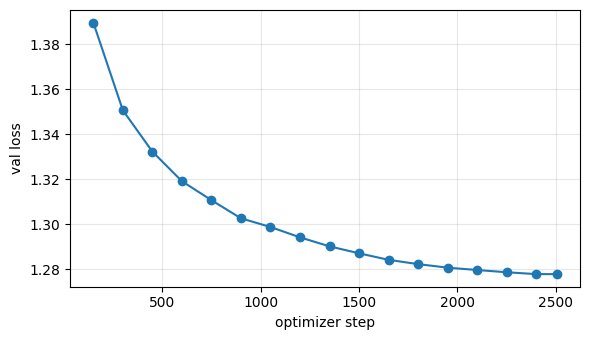

Test words mean=263 min=50 max=399 | extractive fallbacks=0


In [25]:
# Training curve + metadata + prediction sanity checks (v2).
import matplotlib.pyplot as plt
if history:
    plt.figure(figsize=(6,3.5)); plt.plot([h["step"] for h in history],[h["val_loss"] for h in history],"o-")
    plt.xlabel("optimizer step"); plt.ylabel("val loss"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(ROOT/"training_curve.png",dpi=120); plt.show()
lens=np.array([len(x["summary"].split()) for x in test_preds])
fallback_count=sum(x["summary"]==fallback_summary(r["document"]) for x,r in zip(test_preds,test_rows))
print(f"Test words mean={lens.mean():.0f} min={lens.min()} max={lens.max()} | extractive fallbacks={fallback_count}")
assert [x["id"] for x in test_preds]==[str(r["id"]) for r in test_rows]
json.dump({"experiment":"Phase6-Exp5-Model4-Houlsby","bottleneck":ADAPTER_BOTTLENECK,"epochs":EPOCHS,"lr":LR,
           "grad_accum":GRAD_ACCUM,"max_source_tokens":MAX_SOURCE_TOKENS,"max_target_tokens":MAX_TARGET_TOKENS,
           "best_val_loss":best_val,"selected_decoding":best_cfg,"decode_sweep":decode_results,"decode_selection_metric":"BERTScore_F1",
           "final_validation":final_scores,"seed":SEED},open(ROOT/"experiment_metadata.json","w"),indent=2)
